# Tugas Praktikum JS06 - Regresi

## Multiple Linear Regression: Medical Cost Personal Datasets

Dataset yang digunakan adalah **Medical Cost Personal Datasets** (`insurance.csv`) yang berisi 1.338 baris dan 7 kolom. Dataset ini digunakan untuk memprediksi biaya medis tahunan (`charges`) berdasarkan karakteristik peserta asuransi.

| Variabel | Deskripsi |
|---|---|
| `age` | Usia peserta asuransi (tahun) |
| `sex` | Jenis kelamin (`female`, `male`) |
| `bmi` | Body Mass Index |
| `children` | Jumlah anak/tanggungan |
| `smoker` | Status merokok (`no`, `yes`) |
| `region` | Wilayah tempat tinggal (`northeast`, `northwest`, `southeast`, `southwest`) |
| `charges` | Biaya medis personal (target, dalam dolar AS) |

Tujuan tugas: membangun model **multiple linear regression** menggunakan Scikit-Learn, lalu mengevaluasi performanya dengan R-squared, MSE, dan MAE.

## 1. Persiapan Data

In [17]:
# import package
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Sumber dataset

Ketiga file CSV pada folder repo `JS06 - Regresi`:

| File | Dipakai di | Isi |
|---|---|---|
| `dataset.csv` | Praktikum 1 | 1.000 transaksi e-commerce (fitur `Length of Membership`, target `Yearly Amount Spent`) |
| `Posisi_gaji.csv` | Praktikum 2 | 10 posisi, `Level` dan `Gaji` |
| `insurance.csv` | Tugas ini | 1.338 peserta asuransi, 7 kolom, target `charges` |

Di Colab, upload file lewat **panel File** (ikon folder) ke working directory `/content` sebelum menjalankan notebook ini.

In [18]:
# baca data
# File CSV tersedia di folder repo "JS06 - Regresi".
# Di Colab: upload lewat panel File (ikon folder) ke working directory /content, lalu jalankan cell ini.
from pathlib import Path

if not Path('insurance.csv').exists():
    raise FileNotFoundError(
        "insurance.csv belum ada di working directory. "
        "Upload lewat panel File di Colab (file tersedia di folder repo 'JS06 - Regresi')."
    )
print("insurance.csv siap:", Path('insurance.csv').stat().st_size, "byte")

data = pd.read_csv('insurance.csv')
data.head()

insurance.csv siap: 55628 byte


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
# ukuran data
print('Jumlah baris dan kolom:', data.shape)

# info data
data.info()

Jumlah baris dan kolom: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
# deskripsi data
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
# cek missing value dan data duplikat
print('Jumlah missing value:', data.isnull().sum().sum())
print('Jumlah baris duplikat:', data.duplicated().sum())

# ringkasan data kategorikal
data.describe(include='object')

Jumlah missing value: 0
Jumlah baris duplikat: 1


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


Dataset tidak memiliki missing value. Terdapat 1 baris duplikat, tetapi data tetap digunakan karena profil yang identik belum tentu berasal dari individu yang sama.

## 2. Visualisasi Data

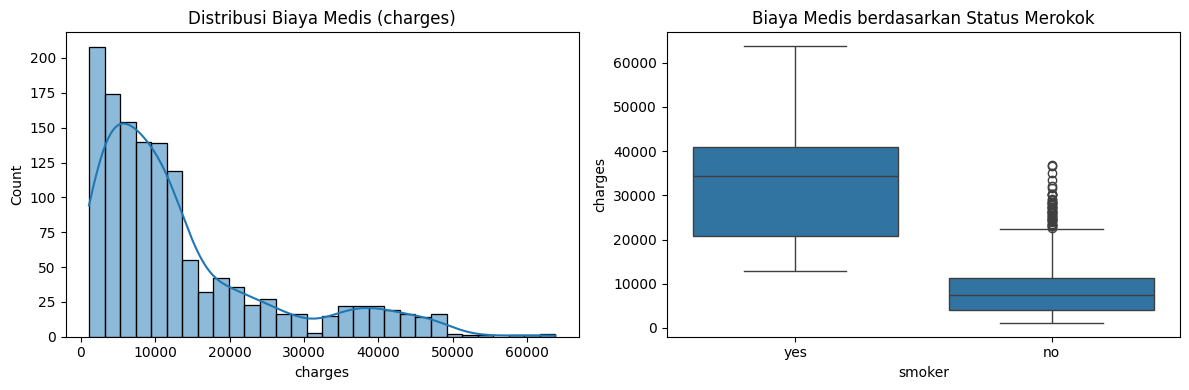

In [6]:
# distribusi target dan hubungan status merokok dengan biaya medis
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data['charges'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribusi Biaya Medis (charges)')
axes[0].set_xlabel('charges')

sns.boxplot(data=data, x='smoker', y='charges', ax=axes[1])
axes[1].set_title('Biaya Medis berdasarkan Status Merokok')
axes[1].set_xlabel('smoker')
axes[1].set_ylabel('charges')

plt.tight_layout()
plt.show()

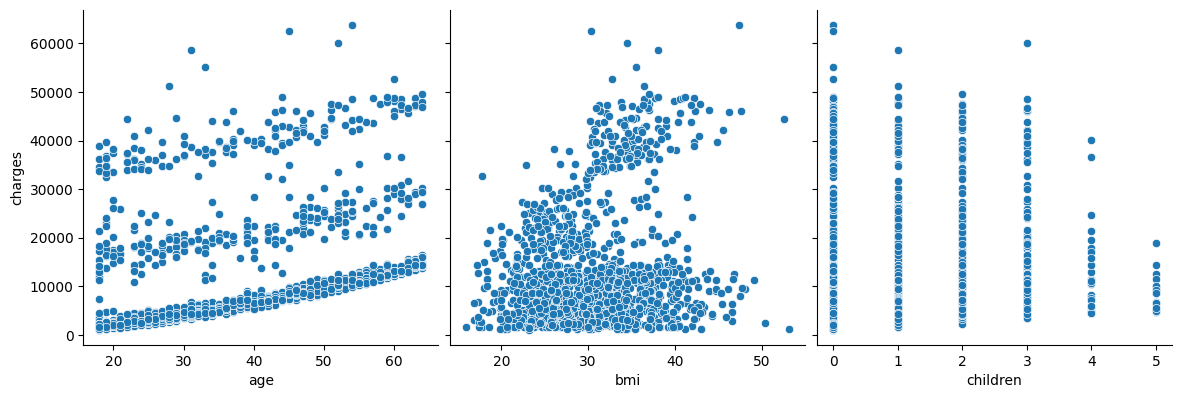

In [7]:
# hubungan fitur numerik dengan target
sns.pairplot(data, x_vars=['age', 'bmi', 'children'],
             y_vars='charges', height=4, aspect=1, kind='scatter')
plt.show()

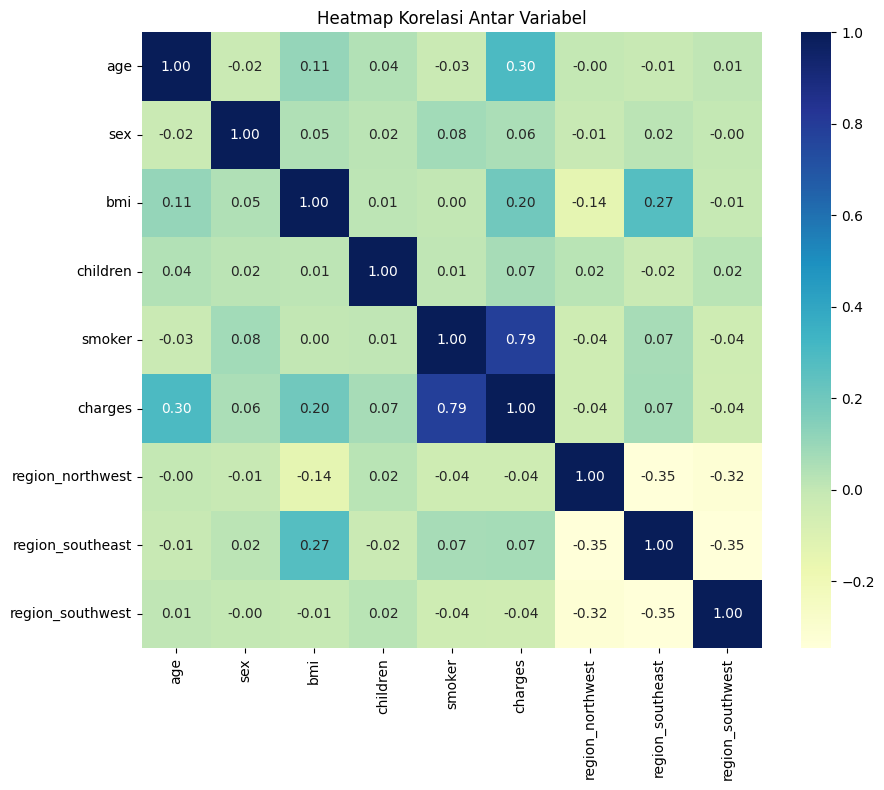

In [8]:
# encoding sementara hanya untuk menghitung korelasi
data_corr = data.copy()
data_corr['sex'] = data_corr['sex'].map({'female': 0, 'male': 1})
data_corr['smoker'] = data_corr['smoker'].map({'no': 0, 'yes': 1})
data_corr = pd.get_dummies(data_corr, columns=['region'], drop_first=True)

plt.figure(figsize=(10, 8))
sns.heatmap(data_corr.corr(), cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Heatmap Korelasi Antar Variabel')
plt.show()

Dari heatmap terlihat bahwa `smoker` memiliki korelasi positif paling kuat terhadap `charges`, diikuti oleh `age` dan `bmi`. Korelasi `children`, `sex`, dan `region` relatif lemah.

## 3. Preprocessing Data dan Pemisahan Data

In [9]:
# encoding fitur kategorikal
data_encoded = data.copy()
data_encoded['sex'] = data_encoded['sex'].map({'female': 0, 'male': 1})
data_encoded['smoker'] = data_encoded['smoker'].map({'no': 0, 'yes': 1})
data_encoded = pd.get_dummies(data_encoded, columns=['region'], drop_first=True)

# variabel bebas (X) dan variabel target (y)
X = data_encoded.drop('charges', axis=1)
y = data_encoded['charges']

X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,False,False,True
1,18,1,33.770,1,0,False,True,False
2,28,1,33.000,3,0,False,True,False
3,33,1,22.705,0,0,True,False,False
4,32,1,28.880,0,0,True,False,False


In [10]:
# bagi data menjadi data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

print('Ukuran X_train:', X_train.shape)
print('Ukuran X_test:', X_test.shape)

Ukuran X_train: (936, 8)
Ukuran X_test: (402, 8)


In [11]:
# feature scaling
# Scaling tidak wajib untuk linear regression, tetapi dilakukan agar skala
# antarfitur seragam dan hasilnya konsisten jika dibandingkan dengan model lain.
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
X_train_sc = sc_X.fit_transform(X_train)
X_test_sc = sc_X.transform(X_test)

## 4. Membuat dan Melatih Model Multiple Linear Regression

In [12]:
# training model multiple linear regression
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_sc, y_train)

print('Intercept:', model.intercept_)

koefisien = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model.coef_
})
koefisien

Intercept: 13169.226679668802


,Fitur,Koefisien
0,age,3658.910679
1,sex,-0.031034
2,bmi,1798.523024
3,children,569.495641
4,smoker,9494.708299
5,region_northwest,-324.738293
6,region_southeast,-423.629730
7,region_southwest,-686.507368


In [13]:
# prediksi pada data latih dan data uji
y_train_pred = model.predict(X_train_sc)
y_test_pred = model.predict(X_test_sc)

# bandingkan 5 data aktual dan hasil prediksi pada data uji
hasil_prediksi = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_test_pred
})
hasil_prediksi.head()

,Actual,Predicted
0,1826.84300,4085.112362
1,20177.67113,4331.248681
2,7421.19455,8435.083234
3,1877.92940,3113.711050
4,15518.18025,25704.594920


## 5. Evaluasi Model

In [14]:
# hitung metrik evaluasi
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)
rmse = np.sqrt(mse)

print('R-squared (train):', r2_train)
print('R-squared (test) :', r2_test)
print('MSE (test)       :', mse)
print('MAE (test)       :', mae)
print('RMSE (test)      :', rmse)

R-squared (train): 0.7378638257001522
R-squared (test) : 0.7772310511733103
MSE (test)       : 32345536.748525452
MAE (test)       : 3943.237703947303
RMSE (test)      : 5687.313667147738


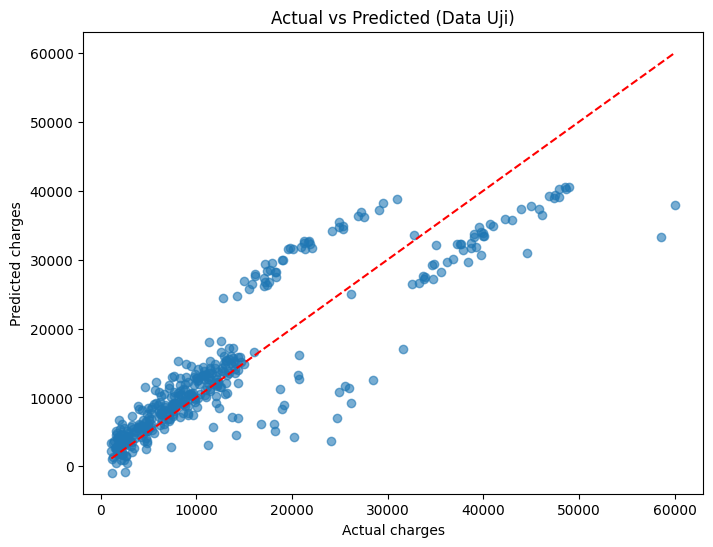

In [15]:
# visualisasi actual vs predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.title('Actual vs Predicted (Data Uji)')
plt.xlabel('Actual charges')
plt.ylabel('Predicted charges')
plt.show()

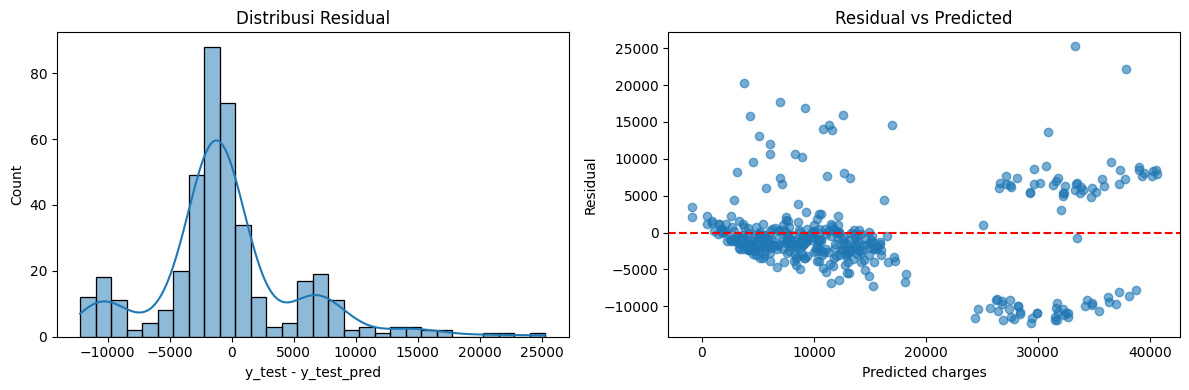

In [16]:
# analisis residual pada data uji
residual = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(residual, bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribusi Residual')
axes[0].set_xlabel('y_test - y_test_pred')

axes[1].scatter(y_test_pred, residual, alpha=0.6)
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_title('Residual vs Predicted')
axes[1].set_xlabel('Predicted charges')
axes[1].set_ylabel('Residual')

plt.tight_layout()
plt.show()

## 6. Analisis Hasil

Berdasarkan pelatihan model dengan `random_state=100` dan pembagian data 7:3, diperoleh hasil evaluasi sebagai berikut:

| Metrik | Nilai |
|---|---|
| R-squared (train) | 0.7379 |
| R-squared (test) | 0.7772 |
| MSE (test) | 32,345,536.75 |
| MAE (test) | 3,943.24 |
| RMSE (test) | 5,687.31 |

**Interpretasi:**

1. Nilai **R-squared data uji sebesar 0.7772** menunjukkan bahwa model mampu menjelaskan sekitar **77.72%** variasi biaya medis (`charges`) pada data uji.
2. R-squared data latih (0.7379) dan data uji (0.7772) tidak berbeda jauh, sehingga model **tidak mengalami overfitting** dan cukup stabil dalam melakukan generalisasi.
3. **MAE sebesar 3,943.24** berarti rata-rata kesalahan prediksi sekitar **$3,943** per peserta. **RMSE sebesar 5,687.31** lebih besar daripada MAE, yang mengindikasikan adanya beberapa kesalahan prediksi besar, umumnya pada peserta dengan biaya medis sangat tinggi.
4. Berdasarkan koefisien model, **`smoker` memiliki pengaruh positif terbesar** terhadap `charges` (9,494.71 per satu standar deviasi), diikuti oleh `age` (3,658.91) dan `bmi` (1,798.52). Hal ini sejalan dengan heatmap korelasi dan menunjukkan bahwa status merokok merupakan faktor dominan dalam menentukan biaya medis.
5. Koefisien `sex` sangat kecil (-0.03) sehingga jenis kelamin hampir tidak berpengaruh setelah variabel lain dikendalikan. Koefisien wilayah bernilai negatif relatif terhadap wilayah `northeast`, yang berarti wilayah lain cenderung memiliki biaya medis lebih rendah dibandingkan `northeast` pada kondisi fitur lain yang sama.

**Keterbatasan model:**

- Model linear mengasumsikan hubungan yang linear dan aditif, sehingga belum menangkap interaksi antarfitur (misalnya interaksi `smoker` dengan `bmi`) maupun pola non-linear.
- Distribusi `charges` cenderung miring ke kanan karena adanya peserta dengan biaya medis sangat tinggi, sehingga nilai RMSE lebih besar daripada MAE.
- Feature scaling tidak mengubah hasil prediksi linear regression, tetapi membuat koefisien dinyatakan dalam satuan standar deviasi sehingga interpretasinya berbeda dari koefisien pada data asli.